In [1]:
# 실습 준비 - 패키지 설치·폰트 (설치는 Colab 에서만 합니다)
#  이 실습에서 새로 설치하는 패키지는 다섯 개입니다 — 교안의 수를 계산한 버전에 맞춰 고정합니다(버전을 올리면 토픽 수가 달라질 수 있습니다).
#    bertopic 0.17.4 · umap-learn 0.5.11 · hdbscan 0.8.42 : 토픽 적합   ·   sentence-transformers 5.3.0 : 문장 인코더
import os
os.environ.setdefault("KIWI_ARCH_TYPE", "balanced")  # CPU 종류(Mac·Colab)와 상관없이 형태소 분석 결과를 같게
#    kiwipiepy 0.23.1 : 한국어 형태소 분석기 Kiwi(과정 결과 명사 열을 받지 못했을 때 같은 버전으로 다시 뽑는다)
#  numpy · pandas · scikit-learn · torch · matplotlib 은 Colab 기본 버전을 그대로 씁니다.
import os, sys, math, time
import subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "bertopic==0.17.4", "umap-learn==0.5.11", "hdbscan==0.8.42",
                    "sentence-transformers==5.3.0", "kiwipiepy==0.23.1"], check=False)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import warnings; warnings.filterwarnings("ignore")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")   # 문장 인코더의 토큰 분리기가 경고를 쏟지 않게

# 한글 폰트 — Colab 이면 나눔고딕을 설치한 뒤 그 ttf 를 폰트 목록에 **직접** 등록한다.
#  설치는 디스크에 파일만 만든다. 이미 떠 있는 폰트 목록은 그 사실을 모르므로 addfont 로
#  등록해야 이름이 보인다(등록하지 않으면 DejaVu Sans 로 밀려 한글이 전부 □ 로 나온다).
import glob, shutil
if IN_COLAB and shutil.which("apt-get"):
    subprocess.run(["apt-get", "-y", "-qq", "install", "fonts-nanum"], check=False)
for _p in glob.glob("/usr/share/fonts/truetype/nanum/Nanum*.ttf"):   # 설치 여부와 무관하게 한 번
    try: fm.fontManager.addfont(_p)
    except Exception: pass
try: fm._get_font.cache_clear()
except Exception: pass
installed = {f.name for f in fm.fontManager.ttflist}
FONT = next((n for n in ["Pretendard", "Apple SD Gothic Neo", "NanumGothic"] if n in installed), "DejaVu Sans")
plt.rcParams["font.family"] = FONT
plt.rcParams["axes.unicode_minus"] = FONT in {"Pretendard", "DejaVu Sans"}   # 나머지 폰트에는 U+2212 가 없다
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}   # 그림마다 폭이 깎이지 않게
plt.rcParams["figure.dpi"] = plt.rcParams["savefig.dpi"] = 150       # 폭 FIG_W x 150dpi = 1500px 고정
plt.rcParams["figure.autolayout"] = True
plt.rcParams.update({"font.size": 11, "axes.titlesize": 15, "axes.labelsize": 12,
                     "legend.fontsize": 11, "figure.titlesize": 17, "font.weight": "regular",
                     "text.color": "black", "axes.labelcolor": "black", "axes.titlecolor": "black",
                     "axes.edgecolor": "#757575", "xtick.color": "#757575", "ytick.color": "#757575",
                     "xtick.labelcolor": "black", "ytick.labelcolor": "black",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False})

# 이 실습의 그림 전체가 함께 쓰는 색 — 기준선=남색, 관측=파랑, 강조=하늘색, 문맥=회색
COL = {"남색": "#051C2C", "파랑": "#2251FF", "하늘색": "#00A9F4",
       "회색": "#757575", "연회색": "#B3B3B3"}
FIG_W = 10.0     # 캔버스 폭은 이 실습의 그림 모두 이 값으로 고정하고 높이만 그림마다 조절한다

from importlib.metadata import version as _ver, PackageNotFoundError
_want = {"bertopic": "0.17.4", "umap-learn": "0.5.11", "hdbscan": "0.8.42",
         "sentence-transformers": "5.3.0", "kiwipiepy": "0.23.1"}
_have = {}
for _name in _want:
    try:
        _have[_name] = _ver(_name)
    except PackageNotFoundError:
        _have[_name] = "없음"
print("사용 폰트:", FONT, "| 색 팔레트 준비 완료 |", " · ".join(f"{k} {v}" for k, v in _have.items()))
_diff = [k for k in _want if _have[k] != _want[k]]
if _diff:
    print("참고 — 교안의 수는 위 다섯 버전에서 계산했습니다. 버전이 다른 패키지(" + " · ".join(_diff)
          + ")가 있어 토픽 수가 조금 다를 수 있습니다. 채점은 범위로 합니다.")

사용 폰트: DejaVu Sans | 색 팔레트 준비 완료 | bertopic 0.17.4 · umap-learn 0.5.12 · hdbscan 0.8.44 · sentence-transformers 6.2.0 · kiwipiepy 0.24.0
참고 — 교안의 수는 위 다섯 버전에서 계산했습니다. 버전이 다른 패키지(umap-learn · hdbscan · sentence-transformers · kiwipiepy)가 있어 토픽 수가 조금 다를 수 있습니다. 채점은 범위로 합니다.


In [2]:

# ===== 한글 폰트 설정 =====
font_path = "C:/Windows/Fonts/malgun.ttf"
fm.fontManager.addfont(font_path)
plt.rcParams["font.family"] = fm.FontProperties(fname=font_path).get_name()
plt.rcParams["axes.unicode_minus"] = False

표 1 · 최소 군집 크기 30 과 100 을 시드 0 · 1 · 2 로 적합한 결과
 최소 군집 크기  시드  토픽 수(개)  이상치 비율(%)
       30   0      102      35.10
       30   1       96      32.98
       30   2      103      33.62
      100   0       40      33.05
      100   1       40      33.70
      100   2       40      32.07


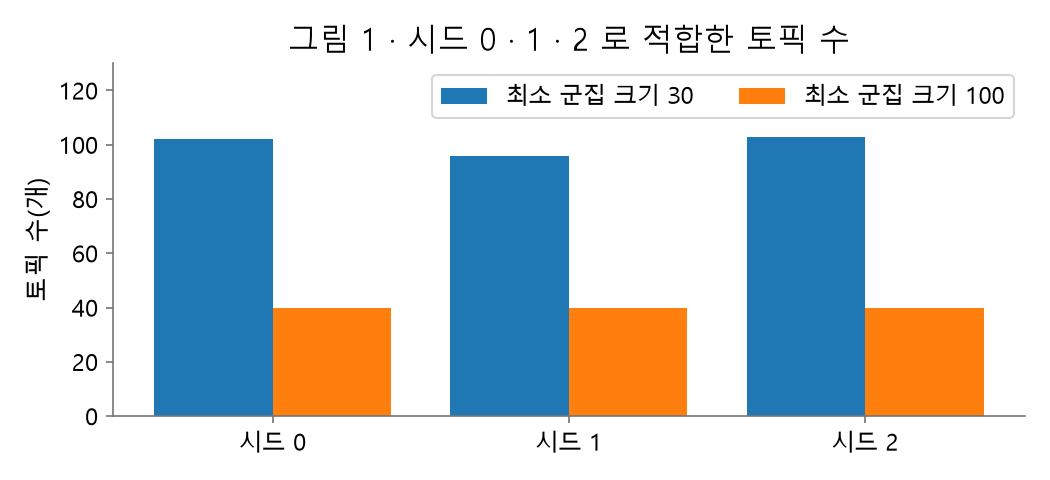


표 2 · 시드 0 의 토픽 0 민원이 시드 1 · 2 에서 받은 토픽 번호 (건)
  시드 0 의 토픽 0 : 1,525건
  시드 1 에서     : 토픽 1 1,450건 · 이상치 74건 · 토픽 29 1건
  시드 2 에서     : 토픽 0 1,514건 · 이상치 10건 · 토픽 29 1건

표 3 · 토픽 1 의 상위 단어 5개와 무작위로 고른 민원 5건
  상위 단어 : 여행 · 항공 · 취소 · 예약 · 코로나  (토픽 1 은 1,484건)
  민원 1    : 항공권 발권 후 환불지연 신고문의
  민원 2    : 해외여행 취소 환불 규정 문의
  민원 3    : 여행 취소 후 환불규정을 알기원함.
  민원 4    : 굿네이버스 동의없이 코로나후원 부당
  민원 5    : 호텔 이용불가에 따른 환불거부


In [3]:
# 오늘의 준비 — 읽고 실행만 합니다
# 토픽 배정 파일과 민원 원자료로 표 1～3 과 그림 1 을 만듭니다. 임베딩도 적합도 하지 않습니다. 처음 한 번은 원자료를 받느라 30초 안팎 걸립니다
import os, re, time, hashlib, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 원자료 — 원 출처 URL · 파일 이름 · SHA-256(2026-09-24 확인) · 데이터 페이지
RAW_FILES = {
    "complaints": ("https://www.data.go.kr/cmm/cmm/fileDownload.do?"
                   "atchFileId=FILE_000000002610054&fileDetailSn=1&insertDataPrcus=N",
                   "kftc_complaints_1.csv",
                   "50c098fea2ec1d05191d07c45cd0f75b4d0ac3b5e5ac36910fe40f2aab699ebe",
                   "https://www.data.go.kr/data/15098314/fileData.do"),
}
DATA_URL = "https://github.com/studio-js/korean-cx-text/raw/main/data"   # 과정 결과(명사 열 · 토픽 배정)를 받는 주소
MIRROR_URL = "https://github.com/studio-js/korean-cx-text/raw/main/raw"  # 과정 복제본: 원 출처와 같은 바이트, 먼저 받는 곳
SUBDIRS = ("", "cache", "raw", "processed")                              # 자료 폴더 안에서 찾는 차례


def data_dir():
    # 자료 폴더: 환경변수 NLP_DATA_DIR 이 있으면 그 폴더, 없으면 ./nlp_data
    return os.environ.get("NLP_DATA_DIR", "nlp_data")


def find_local(name):
    # 자료 폴더 → cache/ → raw/ → processed/ 순서로 찾아 처음 나온 경로, 없으면 None
    for sub in SUBDIRS:
        path = os.path.join(data_dir(), sub, name)
        if os.path.isfile(path):
            return path
    return None


def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _download(url, path, retries=3):
    # url 을 path.part 로 받아 두고 성공하면 True — 실패하면 세 번까지 다시 시도
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    for i in range(retries):
        try:
            urllib.request.urlretrieve(url, path + ".part")
            return True
        except Exception as e:
            print(f"받기 실패 {i + 1}/{retries}: {e}")
            time.sleep(2 * (i + 1))
    return False


def _fetch(url, name, sha=None, strict=False):
    # 로컬에 있으면 그 경로, 없으면 url 에서 받아 SHA-256 확인 뒤 자료 폴더/cache/ 에 두고 경로를 반환함(받지 못하면 None)
    path = find_local(name)
    if path is None:
        path = os.path.join(data_dir(), "cache", name)
        if not _download(url, path):
            return None
        if strict and sha and sha256_of(path + ".part") != sha:
            os.remove(path + ".part")
            raise RuntimeError(f"받은 {name} 의 SHA-256 이 맞지 않습니다. 다시 실행해 보세요.")
        os.replace(path + ".part", path)
    return path


def fetch_raw(name):
    # 원자료 경로: 로컬을 먼저 보고, 없으면 과정 복제본(MIRROR_URL) → 원 출처 URL 순서로 받음
    url, fname, sha, page = RAW_FILES[name]
    path = find_local(fname)
    if path is None:
        path = _fetch(f"{MIRROR_URL}/{fname}", fname)
        if path is not None and sha256_of(path) != sha:  # 복제본이 다르면 버리고 원 출처로
            os.remove(path)
            path = None
    if path is None:
        path = _fetch(url, fname)
    if path is None:
        raise RuntimeError(f"원 출처에서 파일을 받지 못했습니다. 데이터 페이지: {page}")
    if sha256_of(path) != sha:
        print(f"원 출처 파일이 바뀌었습니다. 결과 수가 교안과 다를 수 있습니다(데이터 페이지: {page})")
    return path


def fetch_precomputed(name, sha=None):
    # 과정 결과 파일 경로: 로컬을 먼저 보고, 없으면 DATA_URL/name 에서 받음. 받지 못하면 None
    return _fetch(f"{DATA_URL}/{name}", name, sha, strict=True)


# 민원 파일 읽기 — 문서 비율을 배울 때와 같은 방법으로: 시험 입력·빈 민원 제목 행을 빼고, 전화번호 형태를 [전화번호] 로 바꾼다
TEST_INPUT_RE = re.compile(
    r"(?i)^\s*(?:test|테스트)\s*(?:입니다)?\s*\.?\s*$"
    r"|IN-TEST"
    r"|(?:인바운드|아웃바운드|녹취|수화기).*테스트|테스트.*(?:인바운드|아웃바운드|녹취|수화기)"
    r"|^\s*자동차\s*(?:상담\s*)?테스트"
    r"|^\s*\d{8}\s*[-_ ].*테스트"
    r"|테스트\s*데이터|상담\s*(?:전화\s*)?테스트|전화\s*테스트|헬프데스크\s*시험|^\s*일반\s*테스트")
EMPTY_TITLE_RE = re.compile(r"^[^가-힣A-Za-z]*$")   # 한글 음절도 로마자도 없는 민원 제목(「-」「.」「0」「ㅇ」)
PHONE_RE = re.compile(r"(?<!\d)(?:01[016789]|0\d{1,2})[-.)\s]{0,2}\d{3,4}[-.\s]\d{4}(?!\d)")


def read_complaints(path, verbose=True):
    # 민원 파일(cp949) 읽기 → 열 이름에서 괄호 안 영문을 떼고, 시험 입력·빈 민원 제목 행을 빼고, 전화번호 형태를 [전화번호] 로 바꾼다
    raw = pd.read_csv(path, encoding="cp949", dtype=str)
    df = raw.rename(columns=lambda c: c.split("(")[0].strip())
    df.insert(0, "row_id", range(len(df)))          # 원자료의 행 번호(0부터)
    title = df["사건제목"].fillna("").str.strip()
    is_test = title.str.contains(TEST_INPUT_RE)
    is_empty = title.str.match(EMPTY_TITLE_RE) & ~is_test
    df = df[~is_test & ~is_empty].copy()
    title = title[df.index]
    df["사건제목"] = title.map(lambda t: PHONE_RE.sub("[전화번호]", t))
    df = df.reset_index(drop=True)
    if verbose:
        print(f"민원 원본 {len(raw):,}행 → 시험 입력 {int(is_test.sum())}행·빈 민원 제목 {int(is_empty.sum())}행 제거"
              f" → {len(df):,}행")
    return df


def sample_rows(df, n, seed=0):
    # 고정 표본: 같은 입력과 같은 seed 면 같은 행이 같은 순서로 나온다
    return df.sample(n=n, random_state=seed)




def noun_lists(titles):
    # 과정 결과 명사 열을 받지 못했을 때만 — 같은 Kiwi 버전(0.23.1 기본 사전)으로 명사(NNG·NNP)를 나온 순서대로 다시 뽑는다
    from kiwipiepy import Kiwi
    os.environ.setdefault("KIWI_ARCH_TYPE", "balanced")  # CPU 종류(Mac·Colab)와 상관없이 형태소 분석 결과를 같게
    kiwi = Kiwi(num_workers=2)
    return [[t.form for t in toks if t.tag in ("NNG", "NNP")] for toks in kiwi.tokenize(list(titles))]


# 토픽 배정 파일 — 민원마다 설정별 토픽 번호. 열 이름 topic_m30_s1 은 「최소 군집 크기 30 · 시드 1」, topic_s0 은 「100 · 시드 0」
_topics_path = fetch_precomputed("topics_complaints.parquet")
if _topics_path is None:
    raise RuntimeError("토픽 배정 파일(topics_complaints.parquet)을 받지 못했습니다. 인터넷 연결을 확인하고 이 셀을 다시 실행합니다")
FITS = pd.read_parquet(_topics_path).sort_values("rank").reset_index(drop=True)
N_ALL = len(FITS)                                         # 이상치까지 포함한 민원 수

# 표 1 — 최소 군집 크기 30 과 100 을 시드 0 · 1 · 2 로 적합한 결과
COLS = {(30, 0): "topic_m30_s0", (30, 1): "topic_m30_s1", (30, 2): "topic_m30_s2",
        (100, 0): "topic_s0", (100, 1): "topic_s1", (100, 2): "topic_s2"}
seed_rows = []
for (mcs, seed), col in COLS.items():
    t = FITS[col].to_numpy()
    seed_rows.append({"최소 군집 크기": mcs, "시드": seed, "토픽 수(개)": int(t.max()) + 1,
                      "이상치 비율(%)": round(100 * (t == -1).mean(), 2)})
seed_table = pd.DataFrame(seed_rows)
print("표 1 · 최소 군집 크기 30 과 100 을 시드 0 · 1 · 2 로 적합한 결과")
print(seed_table.to_string(index=False))

fig, ax = plt.subplots(figsize=(7, 3.2))
for i, mcs in enumerate((30, 100)):                       # 시드마다 막대 둘 — 왼쪽 30, 오른쪽 100
    part = seed_table[seed_table["최소 군집 크기"] == mcs]
    ax.bar(part["시드"] + 0.4 * i - 0.2, part["토픽 수(개)"], width=0.4, label=f"최소 군집 크기 {mcs}")
ax.set_xticks([0, 1, 2], ["시드 0", "시드 1", "시드 2"])
ax.set_ylabel("토픽 수(개)")
ax.set_ylim(0, 130)                                       # 범례가 막대를 가리지 않게 위를 비운다
ax.set_title("그림 1 · 시드 0 · 1 · 2 로 적합한 토픽 수")
ax.legend(ncol=2, loc="upper right")
plt.show()

# 표 2 — 최소 군집 크기 100 · 시드 0 의 토픽 0 민원이 시드 1 · 2 에서 받은 토픽 번호
is_t0 = FITS["topic_s0"] == 0
moved = {seed: FITS.loc[is_t0, f"topic_s{seed}"].value_counts() for seed in (1, 2)}
print()
print("표 2 · 시드 0 의 토픽 0 민원이 시드 1 · 2 에서 받은 토픽 번호 (건)")
print(f"  시드 0 의 토픽 0 : {int(is_t0.sum()):,}건")
for seed, vc in moved.items():
    top3 = " · ".join(f"토픽 {k} {n:,}건" if k != -1 else f"이상치 {n:,}건" for k, n in vc.head(3).items())
    print(f"  시드 {seed} 에서     : {top3}")

# 표 3 — 토픽 1 의 c-TF-IDF 상위 단어 5개와 무작위로 고른 민원 5건(시드 0)
_sample = sample_rows(read_complaints(fetch_raw("complaints"), verbose=False), 20000, seed=0)[["row_id", "사건제목"]]
TITLES = FITS[["row_id", "topic_s0"]].merge(_sample, on="row_id", how="left")
_nouns_path = fetch_precomputed("complaints_nouns.parquet")
if _nouns_path is not None:
    TITLES = TITLES.merge(pd.read_parquet(_nouns_path), on="row_id", how="left")
else:
    TITLES["명사"] = noun_lists(TITLES["사건제목"])
from sklearn.feature_extraction.text import CountVectorizer
STOP_COMPLAINTS = ["문의", "요청", "관련", "요구", "건", "후", "상담", "불만", "피해"]   # 불용어 9개
_joined = TITLES.groupby("topic_s0")["명사"].apply(lambda s: " ".join(w for ws in s for w in ws))   # 토픽 문서 41개
_cv = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, min_df=2, stop_words=STOP_COMPLAINTS)
_X = _cv.fit_transform(_joined.values)
_vocab = np.array(_cv.get_feature_names_out())
_tot = np.asarray(_X.sum(axis=1)).ravel()                 # 토픽 문서마다 명사 수
_f = np.asarray(_X.sum(axis=0)).ravel()                   # 단어마다 전체 횟수
_w = _X.multiply(1 / _tot[:, None]).toarray() * np.log(1 + int(_tot.mean()) / _f)
top_words1 = list(_vocab[np.argsort(-_w[list(_joined.index).index(1)])[:5]])
pos1 = np.flatnonzero(TITLES["topic_s0"].to_numpy() == 1)
pick1 = np.random.default_rng(0).choice(pos1, 5, replace=False)
print()
print("표 3 · 토픽 1 의 상위 단어 5개와 무작위로 고른 민원 5건")
print(f"  상위 단어 : {' · '.join(top_words1)}  (토픽 1 은 {len(pos1):,}건)")
for n, p in enumerate(pick1, 1):
    print(f"  민원 {n}    : {TITLES['사건제목'].iloc[p]}")

같은 토픽 표를 다시 만들 때 필요한 기록
예를 들어 동료의 민원 토픽 표 아래에 「문장 인코더 KURE-v1 · 최소 군집 크기 100」만 적혀 있다고 합시다. 같은 표를 다시 만들려면 무엇을 더 알아야 할까요?

B UMAP 의 이웃 수 · 시드 · 불용어 목록

표를 다시 만들려면 결과가 아니라 결과를 낸 설정이 있어야 합니다. 이론에서 기록할 설정은 다섯 가지였습니다. 문장 인코더 · UMAP 의 이웃 수 · 시드 · 최소 군집 크기 · 불용어 목록입니다. 표 아래에는 그 가운데 두 가지만 있어 세 가지가 빠졌습니다.

이름 후보와 대표 문서: 적합이 끝난 뒤에 읽고 정한 결과입니다. 이것만으로는 같은 토픽 번호를 다시 얻지 못합니다.
토픽 수와 이상치 비율: 다시 만든 표가 같은지 비교할 때 보는 값입니다. 표를 다시 만드는 설정은 아닙니다.
불용어 목록은 토픽 배정을 바꾸지 않지만 상위 단어를 바꿉니다. 그래서 다섯 가지를 모두 표 아래에 적습니다.

핵심 키워드: 설정 다섯 가지, 결과와 설정의 차이, 다시 만들 수 있는 표

토픽 12개로 정하기 전에 확인할 것
예를 들어 최소 군집 크기를 키웠더니 토픽이 12개로 줄어 표 한 장에 들어갔다고 합시다. 그런데 가장 큰 토픽 하나가 전체 민원의 31% 입니다. 이 값으로 정하기 전에 무엇을 확인할지 한두 문장으로 적어 보세요.

군집을 키워 너무 많은 범위를 군집하여 이상치 또한 많아졌는지 확인해야할 것 같습니다.

가장 큰 토픽의 상위 단어와 무작위 원문을 읽어 여러 주제가 함께 들어 있는지 확인합니다. 시드를 바꿔도 토픽 수가 같은지와 이상치 비율도 함께 봅니다.

표 한 장에 맞는 토픽 수는 최소 군집 크기를 고르는 기준이 아닙니다. 이론의 기준은 두 가지였습니다. 시드를 바꿔도 토픽 수가 같은지, 이상치 비율이 얼마인지입니다. 표의 항목 수는 표를 만들 때 맞춥니다.

전체의 31% 인 토픽은 한 주제로 보기에 큽니다. 서로 다른 불만이 한 군집에 모였을 수 있습니다. 그러면 이 토픽으로는 무엇을 고칠지 정할 수 없습니다.

여러 주제가 함께 있다면 더 작은 최소 군집 크기로 적합합니다. 그다음 표에서 크기 순으로 자르거나 같은 주제끼리 합쳐 한 장에 맞춥니다.

모범 답: 「가장 큰 토픽의 상위 단어와 무작위 민원 여러 건을 읽어 여러 주제가 함께 있는지 본다. 시드를 바꿔도 토픽이 12개인지와 이상치 비율도 확인한다.」

채점할 때 볼 것

① 가장 큰 토픽의 상위 단어나 원문을 읽는다고 적었는가

② 시드를 바꿔도 토픽 수가 같은지, 이상치 비율이 얼마인지를 함께 본다고 적었는가

③ 여러 주제가 함께 있다면 더 작은 값으로 적합하고 표에서 자르거나 합친다는 다음 행동을 적었는가

핵심 키워드: 표 한 장에 맞는 토픽 수 ≠ 고르는 기준, 가장 큰 토픽의 원문, 시드와 이상치 비율

민원 토픽 표를 만들 최소 군집 크기
「오늘의 준비」 셀을 실행하면 나오는 「표 1 · 최소 군집 크기 30 과 100 을 시드 0 · 1 · 2 로 적합한 결과」와 「그림 1 · 시드 0 · 1 · 2 로 적합한 토픽 수」를 봅니다. 민원 토픽 표는 어느 값으로 만들까요?

B 100: 세 시드 모두 토픽 수가 같고 이상치 비율은 30 과 비슷하다

최소 군집 크기는 시드를 바꿔도 토픽 수가 같은지와 이상치 비율로 고릅니다. 표 1 에서 100 은 세 시드 모두 토픽 40개입니다. 30 은 102 · 96 · 103개로 시드마다 다릅니다. 이상치 비율은 30 이 약 33～35%, 100 이 약 32～34% 로 비슷합니다.

30: 토픽이 많아도 시드를 바꾸면 수가 달라집니다. 다시 적합할 때마다 다른 표가 나옵니다.
정할 수 없다: 이상치 비율이 비슷하면 시드를 바꿔도 토픽 수가 같은 쪽을 고릅니다.
그래서 민원 토픽 표는 최소 군집 크기 100 으로 만듭니다. 표 한 장의 항목 수는 표를 만들 때 맞춥니다.

핵심 키워드: 시드를 바꿔도 같은 토픽 수, 이상치 비율, 최소 군집 크기 100

시드를 바꾼 표의 토픽 0
「오늘의 준비」 셀을 실행하면 나오는 「표 2 · 시드 0 의 토픽 0 민원이 시드 1 · 2 에서 받은 토픽 번호 (건)」을 봅니다. 시드 1 로 다시 적합한 표의 토픽 0 을 시드 0 표의 토픽 0 과 비교해도 될까요?

C 안 된다: 같은 민원 대부분이 시드 1 에서는 토픽 1 이다

토픽 번호는 적합할 때마다 건수가 많은 차례로 새로 매겨집니다. 표 2 에서 시드 0 의 토픽 0 민원 1,525건 가운데 약 1,450건이 시드 1 에서는 토픽 1 입니다. 시드 2 에서는 약 1,510건이 토픽 0 이라 번호가 우연히 같습니다.

같은 번호는 같은 주제: 시드 1 에서는 번호가 바뀌었습니다. 같은 설정이어도 토픽 번호는 바뀔 수 있습니다.
토픽이 40개라 번호도 같다: 토픽 수가 같아도 토픽마다 건수가 조금씩 달라 크기 차례가 바뀝니다. 그러면 번호도 바뀝니다.
그래서 다시 적합한 표끼리는 토픽 번호가 아니라 토픽 수와 이상치 비율로 비교합니다. 미션 1 에서 직접 적합한 표의 번호도 토픽 배정 파일과 다를 수 있습니다.

핵심 키워드: 토픽 번호는 적합마다 새로 매김, 토픽 수와 이상치 비율로 비교, 시드

토픽 1 의 이름 후보
「오늘의 준비」 셀을 실행하면 나오는 「표 3 · 토픽 1 의 상위 단어 5개와 무작위로 고른 민원 5건」을 봅니다. 토픽 1 의 이름을 「코로나로 취소한 여행 · 항공 예약」으로 정해도 될까요?

A 아직 후보로 둔다: 숙박 환불과 여행이 아닌 민원이 함께 있다

토픽 이름은 상위 단어가 아니라 무작위 원문을 읽은 뒤 정합니다. 표 3 의 민원 5건 가운데 4건은 여행 · 항공 · 숙박의 취소와 환불 이야기입니다. 「호텔 이용불가에 따른 환불거부」는 숙박이라 주제가 상위 단어보다 넓습니다. 「굿네이버스 동의없이 코로나후원 부당」은 「코로나」만 같고 여행 이야기가 아닙니다.

정한다: 상위 단어는 점수가 큰 명사 몇 개뿐입니다. 민원 5건 가운데 코로나로 취소했다는 여행 민원은 없습니다.
이름을 짓지 않는다: 5건 가운데 4건이 한 주제로 모여 있습니다. 서로 다른 주제가 함께 있는 이상치와 다릅니다.
그래서 토픽 1 은 「여행 · 항공 · 숙박의 취소와 환불」처럼 넓은 후보로 두고, 원문을 더 읽은 뒤 이름을 정합니다.

핵심 키워드: 이름은 원문을 읽은 뒤, 상위 단어보다 넓은 주제, 이상치와 다른 토픽

In [4]:
# 미션 1 · 준비 — 읽고 실행만 합니다. 이 셀이 미션 1 에 쓸 이름을 직접 만듭니다
#  민원 원자료를 과정 복제본에서 한 번 받아 두고(67.9MB), 표본 2만 건의 앞 N 건에 명사 열을 합친 뒤 문장 인코더를 불러 둡니다.
#  임베딩과 토픽 적합은 하지 않아 CPU 에서 10초 안팎입니다. 계산은 PROMPT 셀에서 embed · fit_topics 로 합니다
import os, re, time, hashlib, urllib.request
from decimal import Decimal, ROUND_HALF_UP
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

COL = {"남색": "#051C2C", "파랑": "#2251FF", "하늘색": "#00A9F4",   # 맨 위 셀과 같은 색 · 캔버스 폭 —
       "회색": "#757575", "연회색": "#B3B3B3"}                        #  이 셀만 실행해도 정해집니다
FIG_W = 10.0

# 원자료 — 원 출처 URL · 파일 이름 · SHA-256(2026-09-24 확인) · 데이터 페이지
RAW_FILES = {
    "complaints": ("https://www.data.go.kr/cmm/cmm/fileDownload.do?"
                   "atchFileId=FILE_000000002610054&fileDetailSn=1&insertDataPrcus=N",
                   "kftc_complaints_1.csv",
                   "50c098fea2ec1d05191d07c45cd0f75b4d0ac3b5e5ac36910fe40f2aab699ebe",
                   "https://www.data.go.kr/data/15098314/fileData.do"),
}
DATA_URL = "https://github.com/studio-js/korean-cx-text/raw/main/data"   # 과정 결과(명사 열 · 토픽 배정)를 받는 주소
MIRROR_URL = "https://github.com/studio-js/korean-cx-text/raw/main/raw"  # 과정 복제본: 원 출처와 같은 바이트, 먼저 받는 곳
SUBDIRS = ("", "cache", "raw", "processed")                              # 자료 폴더 안에서 찾는 차례


def data_dir():
    # 자료 폴더: 환경변수 NLP_DATA_DIR 이 있으면 그 폴더, 없으면 ./nlp_data
    return os.environ.get("NLP_DATA_DIR", "nlp_data")


def find_local(name):
    # 자료 폴더 → cache/ → raw/ → processed/ 순서로 찾아 처음 나온 경로, 없으면 None
    for sub in SUBDIRS:
        path = os.path.join(data_dir(), sub, name)
        if os.path.isfile(path):
            return path
    return None


def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _download(url, path, retries=3):
    # url 을 path.part 로 받아 두고 성공하면 True — 실패하면 세 번까지 다시 시도
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    for i in range(retries):
        try:
            urllib.request.urlretrieve(url, path + ".part")
            return True
        except Exception as e:
            print(f"받기 실패 {i + 1}/{retries}: {e}")
            time.sleep(2 * (i + 1))
    return False


def _fetch(url, name, sha=None, strict=False):
    # 로컬에 있으면 그 경로, 없으면 url 에서 받아 SHA-256 확인 뒤 자료 폴더/cache/ 에 두고 경로를 반환함(받지 못하면 None)
    path = find_local(name)
    if path is None:
        path = os.path.join(data_dir(), "cache", name)
        if not _download(url, path):
            return None
        if strict and sha and sha256_of(path + ".part") != sha:
            os.remove(path + ".part")
            raise RuntimeError(f"받은 {name} 의 SHA-256 이 맞지 않습니다. 다시 실행해 보세요.")
        os.replace(path + ".part", path)
    return path


def fetch_raw(name):
    # 원자료 경로: 로컬을 먼저 보고, 없으면 과정 복제본(MIRROR_URL) → 원 출처 URL 순서로 받음
    url, fname, sha, page = RAW_FILES[name]
    path = find_local(fname)
    if path is None:
        path = _fetch(f"{MIRROR_URL}/{fname}", fname)
        if path is not None and sha256_of(path) != sha:  # 복제본이 다르면 버리고 원 출처로
            os.remove(path)
            path = None
    if path is None:
        path = _fetch(url, fname)
    if path is None:
        raise RuntimeError(f"원 출처에서 파일을 받지 못했습니다. 데이터 페이지: {page}")
    if sha256_of(path) != sha:
        print(f"원 출처 파일이 바뀌었습니다. 결과 수가 교안과 다를 수 있습니다(데이터 페이지: {page})")
    return path


def fetch_precomputed(name, sha=None):
    # 과정 결과 파일 경로: 로컬을 먼저 보고, 없으면 DATA_URL/name 에서 받음. 받지 못하면 None
    return _fetch(f"{DATA_URL}/{name}", name, sha, strict=True)


def rnd(x, digits):
    # 십진 값 기준 반올림(끝자리 5 는 올림) — 교안의 수와 같은 방식
    return float(Decimal(f"{float(x):.12g}").quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))


# 민원 파일 읽기 — 문서 비율을 배울 때와 같은 방법으로: 시험 입력·빈 민원 제목 행을 빼고, 전화번호 형태를 [전화번호] 로 바꾼다
TEST_INPUT_RE = re.compile(
    r"(?i)^\s*(?:test|테스트)\s*(?:입니다)?\s*\.?\s*$"
    r"|IN-TEST"
    r"|(?:인바운드|아웃바운드|녹취|수화기).*테스트|테스트.*(?:인바운드|아웃바운드|녹취|수화기)"
    r"|^\s*자동차\s*(?:상담\s*)?테스트"
    r"|^\s*\d{8}\s*[-_ ].*테스트"
    r"|테스트\s*데이터|상담\s*(?:전화\s*)?테스트|전화\s*테스트|헬프데스크\s*시험|^\s*일반\s*테스트")
EMPTY_TITLE_RE = re.compile(r"^[^가-힣A-Za-z]*$")   # 한글 음절도 로마자도 없는 민원 제목(「-」「.」「0」「ㅇ」)
PHONE_RE = re.compile(r"(?<!\d)(?:01[016789]|0\d{1,2})[-.)\s]{0,2}\d{3,4}[-.\s]\d{4}(?!\d)")


def read_complaints(path, verbose=True):
    # 민원 파일(cp949) 읽기 → 열 이름에서 괄호 안 영문을 떼고, 시험 입력·빈 민원 제목 행을 빼고, 전화번호 형태를 [전화번호] 로 바꾼다
    raw = pd.read_csv(path, encoding="cp949", dtype=str)
    df = raw.rename(columns=lambda c: c.split("(")[0].strip())
    df.insert(0, "row_id", range(len(df)))          # 원자료의 행 번호(0부터)
    title = df["사건제목"].fillna("").str.strip()
    is_test = title.str.contains(TEST_INPUT_RE)
    is_empty = title.str.match(EMPTY_TITLE_RE) & ~is_test
    df = df[~is_test & ~is_empty].copy()
    title = title[df.index]
    df["사건제목"] = title.map(lambda t: PHONE_RE.sub("[전화번호]", t))
    df = df.reset_index(drop=True)
    if verbose:
        print(f"민원 원본 {len(raw):,}행 → 시험 입력 {int(is_test.sum())}행·빈 민원 제목 {int(is_empty.sum())}행 제거"
              f" → {len(df):,}행")
    return df


def sample_rows(df, n, seed=0):
    # 고정 표본: 같은 입력과 같은 seed 면 같은 행이 같은 순서로 나온다
    return df.sample(n=n, random_state=seed)


def noun_lists(titles):
    # 과정 결과 명사 열을 받지 못했을 때만 — 같은 Kiwi 버전(0.23.1 기본 사전)으로 명사(NNG·NNP)를 나온 순서대로 다시 뽑는다
    from kiwipiepy import Kiwi
    import os
    os.environ.setdefault("KIWI_ARCH_TYPE", "balanced")  # CPU 종류(Mac·Colab)와 상관없이 형태소 분석 결과를 같게
    kiwi = Kiwi(num_workers=2)
    return [[t.form for t in toks if t.tag in ("NNG", "NNP")] for toks in kiwi.tokenize(list(titles))]


# 실행 설정 — GPU 면 KURE-v1 로 2만 건, 아니면 multilingual-e5-small 로 4천 건 (채점 기준도 이 설정을 따릅니다)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    MODEL_NAME, MODEL_REV, PREFIX, N, MCS = "nlpai-lab/KURE-v1", "8b418a58414668e75532ed045c22d9ca018ae2b2", "", 20000, 100
else:                                          # e5 는 군집용 입력에 「query: 」를 앞에 추가한다
    MODEL_NAME, MODEL_REV, PREFIX, N, MCS = (
        "intfloat/multilingual-e5-small", "614241f622f53c4eeff9890bdc4f31cfecc418b3", "query: ", 4000, 30)
STOP_COMPLAINTS = ["문의", "요청", "관련", "요구", "건", "후", "상담", "불만", "피해"]   # 문서 비율을 배울 때의 불용어 9개 — 상위 단어에서만 뺀다

C = sample_rows(read_complaints(fetch_raw("complaints")), 20000, seed=0).head(N)   # 표본 2만 건(시드 0)의 앞 N 건
C = C[["row_id", "사건제목"]].reset_index(drop=True)
_nouns_path = fetch_precomputed("complaints_nouns.parquet")
if _nouns_path is not None:
    C = C.merge(pd.read_parquet(_nouns_path), on="row_id", how="left")
    _noun_src = "과정 결과 명사 열"
else:
    C["명사"] = noun_lists(C["사건제목"])
    _noun_src = "Kiwi 로 다시 뽑은 명사 열(과정 결과를 받지 못함)"
C["tokdoc"] = C["명사"].map(lambda ws: " ".join(ws))   # 쓸 변수 — 명사를 공백으로 이은 문자열(c-TF-IDF 입력)

from sentence_transformers import SentenceTransformer
ENCODER = SentenceTransformer(MODEL_NAME, device=DEVICE, revision=MODEL_REV)   # revision 을 고정해 교안과 같은 가중치를 불러옵니다(문장 임베딩을 배울 때와 같은 방식)
ENCODER.max_seq_length = 256


def embed(texts):
    # 문장마다 벡터 하나 — DEVICE 에서 64건씩 계산하고, 길이를 1 로 맞춘 float32 numpy 배열(건수 × 차원)로 반환한다
    return ENCODER.encode([PREFIX + t for t in texts], batch_size=64, normalize_embeddings=True,
                          convert_to_numpy=True, show_progress_bar=False).astype(np.float32)


_UMAP_DONE = {}   # (벡터, 시드) → UMAP 으로 줄인 5차원 벡터. 같은 벡터 · 같은 시드면 다시 계산하지 않는다


def _umap5(E, seed):
    from sklearn.neighbors import NearestNeighbors
    from umap import UMAP
    key = (id(E), E.shape, seed)
    if key not in _UMAP_DONE:
        # 가까운 이웃 15개를 정확히 구해 전달한다 — UMAP 의 근사 이웃 찾기는 시드를 고정해도 실행마다 달라진다
        dist, idx = NearestNeighbors(n_neighbors=15, metric="cosine", algorithm="brute").fit(E).kneighbors(E)
        um = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=seed,
                  precomputed_knn=(idx, dist.astype(np.float32), None))
        _UMAP_DONE[key] = (E, um.fit_transform(E).astype(np.float32))   # E 를 함께 붙들어 id 가 다른 배열에 재사용되지 않게
    return _UMAP_DONE[key][1]


def fit_topics(E, docs, mcs, seed=0, stop=STOP_COMPLAINTS):
    """BERTopic 한 번 — 임베딩 E(문장 벡터) → UMAP 5차원(시드 고정) → HDBSCAN(최소 군집 크기 mcs) → c-TF-IDF(docs 의 명사).
    반환하는 것: (model, topics) — topics 는 문서마다 토픽 번호(numpy 배열, 어느 토픽에도 들지 않으면 −1)"""
    from bertopic import BERTopic
    from bertopic.dimensionality import BaseDimensionalityReduction
    from hdbscan import HDBSCAN
    from sklearn.feature_extraction.text import CountVectorizer
    model = BERTopic(
        language="multilingual",                                  # 기본값 "english" 는 한글 상위 단어를 지운다
        umap_model=BaseDimensionalityReduction(),                  # UMAP 은 위 _umap5 에서 이미 계산했다
        hdbscan_model=HDBSCAN(min_cluster_size=mcs, metric="euclidean", cluster_selection_method="eom",
                              prediction_data=True),
        vectorizer_model=CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False,
                                         min_df=2, stop_words=stop),   # 공백으로 나눈 명사를 그대로 집계한다
        calculate_probabilities=False, verbose=False)
    topics, _ = model.fit_transform(list(docs), embeddings=_umap5(E, seed))
    return model, np.asarray(topics)


def representative(model, docs, topics):
    """토픽마다 대표 문서의 위치 — 문서 하나의 c-TF-IDF 벡터와 그 토픽 c-TF-IDF 행의 코사인이 가장 큰 문서(이론 「토픽 이름은 어떻게 정하는가」와 같은 정의).
    반환하는 것: {토픽 번호: docs 안의 위치} (−1 은 포함하지 않는다)"""
    from sklearn.preprocessing import normalize
    D = normalize(model.ctfidf_model.transform(model.vectorizer_model.transform(list(docs))))
    T = normalize(model.c_tf_idf_)
    topics = np.asarray(topics)
    rows = topics + (1 if (topics == -1).any() else 0)          # c_tf_idf_ 의 첫 행은 −1 이 있으면 −1 이다
    sim = np.asarray(D.multiply(T[rows]).sum(axis=1)).ravel()
    return {int(k): int(np.flatnonzero(topics == k)[np.argmax(sim[topics == k])])
            for k in sorted(set(topics.tolist())) if k != -1}


_short = "KURE-v1" if DEVICE == "cuda" else "multilingual-e5-small"
print(f"이번 실행 설정: DEVICE {DEVICE} · {_short} · 민원 {N:,}건 · 최소 군집 크기 {MCS}")
print(f"민원 표본 준비 — {len(C):,}건 · {_noun_src} · 민원 제목 하나의 명사 평균 {C['명사'].map(len).mean():.2f}개")
print("쓸 수 있는 이름 : C · N · MCS · DEVICE · embed · fit_topics · representative · rnd · COL · FIG_W")

민원 원본 499,999행 → 시험 입력 91행·빈 민원 제목 64행 제거 → 499,844행


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1649.53it/s]


이번 실행 설정: DEVICE cpu · multilingual-e5-small · 민원 4,000건 · 최소 군집 크기 30
민원 표본 준비 — 4,000건 · 과정 결과 명사 열 · 민원 제목 하나의 명사 평균 6.07개
쓸 수 있는 이름 : C · N · MCS · DEVICE · embed · fit_topics · representative · rnd · COL · FIG_W


representative (model, docs, topics)
토픽 수 = 20 개
이상치 비율 = 32.85 %


,토픽,건수,비율,상위 단어,대표 문서
0,0,669,16.73,"반품, 배송, 주문, 구매, 환불",623
1,1,298,7.45,"여행, 취소, 항공, 코로나, 예약",3446
2,2,255,6.38,"휴대폰, 개통, 인터넷, 요금, 스마트폰",2472
3,3,217,5.42,"세탁, 배상, 택배, 파손, 분실",181
4,4,132,3.30,"보험, 상담원, 사업자, 확인, 담당자",247
5,5,129,3.23,"냉장고, 수리, 하자, 에어컨, 고장",3663
6,6,122,3.05,"정수기, 렌탈, 코웨이, 지연, 해지",157
7,7,112,2.80,"수술, 치료, 선납, 경우, 부작용",78
8,8,103,2.57,"헬스, 해지, 중도, 환불, 규정",2829
9,9,101,2.53,"자동차, 차량, 중고, 수리, 보증",319


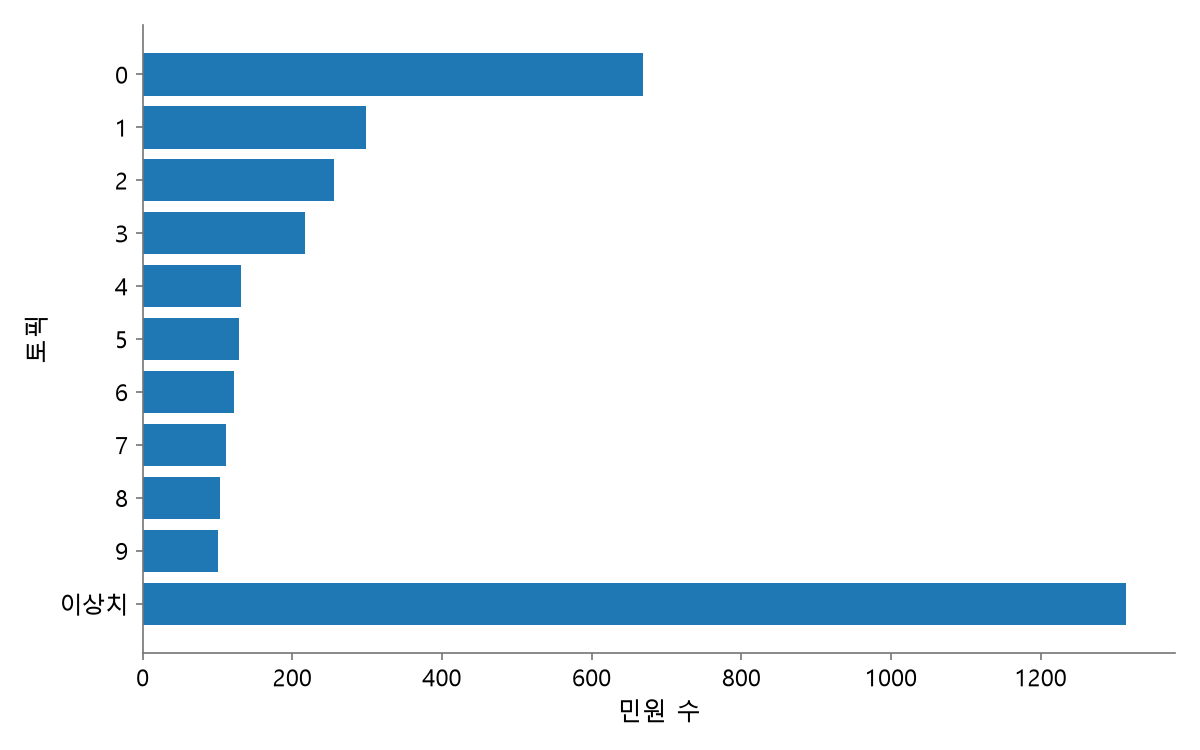

In [5]:
# 미션 1 — 프롬프트   # ai: prompt
# [heavy] 임베딩과 UMAP 을 계산합니다 — CPU 4천 건 20초 안팎, Colab T4 GPU 2만 건 3분 안팎
# PROMPT 를 쓰고 → AI 튜터에 "위 PROMPT 대로 코드를 써 줘" → 「이 셀에 넣기」 → ▶
# 시킬 일은 AI 튜터 대화창이 아니라 아래 PROMPT 따옴표 안에 적습니다. 따옴표 안이 비어 있으면 채점과 완성본 풀이가 잠깁니다
PROMPT = """
미션1 준비셀의 C · N · MCS · embed · fit_topics · representative 그대로 사용
이 미션의 질문: 민원 제목을 직접 적합하면 토픽은 몇 개이고 이상치 비율은 몇 % 일까요?
1. 토픽 수: 개, 정수, 토빅 번호 -1을 뺀 토픽의 수
2. 이상치 비율: %, 소수 둘째자리, 토픽 번호가 -1인 민원 수 / N *100
3. 토픽 표: 열 토픽, 건수, 비율, 상위 단어, 대표 문서 / 내림차순 비율의 분모는 N
4. 그래프
가로축: 민원 수
세로축: 토픽
상위 10토픽과 이상치의 가로막대
"""
# --- 여기부터 AI 코드 ---
import inspect
import pandas as pd
import matplotlib.pyplot as plt

print("representative", inspect.signature(representative))  # 실제 인자 순서 확인용

emb = embed(C["사건제목"].tolist())
model, topics = fit_topics(emb, C["tokdoc"].tolist(), MCS)

topics = pd.Series(topics)
counts = topics.value_counts()

n_topics = int((counts.index != -1).sum())
n_out = int(counts.get(-1, 0))
out_ratio = round(n_out / N * 100, 2)

# 가정: representative(모델, 문서 리스트, 문서별 토픽 번호) -> {토픽 번호: 대표 문서}
rep = representative(model, C["사건제목"].tolist(), topics.tolist())

rows = []
for t, cnt in counts.drop(-1, errors="ignore").sort_values(ascending=False).items():
    words = ", ".join(w for w, _ in model.get_topic(t)[:5])
    rows.append({"토픽": t, "건수": int(cnt), "비율": round(cnt / N * 100, 2),
                 "상위 단어": words, "대표 문서": rep[t] if t in rep else ""})
rows.append({"토픽": -1, "건수": n_out, "비율": out_ratio,
             "상위 단어": "", "대표 문서": ""})
table = pd.DataFrame(rows)

print(f"토픽 수 = {n_topics} 개")
print(f"이상치 비율 = {out_ratio:.2f} %")
display(table)

plot = pd.concat([table.iloc[:-1].head(10), table.iloc[[-1]]])
labels = [("이상치" if t == -1 else str(t)) for t in plot["토픽"]]
plt.figure(figsize=(8, 5))
plt.barh(labels[::-1], plot["건수"].tolist()[::-1])
plt.xlabel("민원 수")
plt.ylabel("토픽")
plt.tight_layout()
plt.show()

In [6]:
# 미션 2 · 준비 — 읽고 실행만 합니다. 이 셀이 미션 2 에 쓸 이름을 직접 만듭니다
#  미션 1 의 결과가 아니라 과정 결과(토픽 배정 버전 topics-v1-20260924, KURE-v1 · 최소 군집 크기 100 · 시드 0)를 읽습니다.
#  모두 같은 표로 채점하고, 임베딩도 적합도 하지 않아 CPU 에서 몇 초면 끝납니다
import os, re, time, hashlib, urllib.request
from decimal import Decimal, ROUND_HALF_UP
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

COL = {"남색": "#051C2C", "파랑": "#2251FF", "하늘색": "#00A9F4",   # 맨 위 셀과 같은 색 · 캔버스 폭 —
       "회색": "#757575", "연회색": "#B3B3B3"}                        #  이 셀만 실행해도 정해집니다
FIG_W = 10.0

# 원자료 — 원 출처 URL · 파일 이름 · SHA-256(2026-09-24 확인) · 데이터 페이지
RAW_FILES = {
    "complaints": ("https://www.data.go.kr/cmm/cmm/fileDownload.do?"
                   "atchFileId=FILE_000000002610054&fileDetailSn=1&insertDataPrcus=N",
                   "kftc_complaints_1.csv",
                   "50c098fea2ec1d05191d07c45cd0f75b4d0ac3b5e5ac36910fe40f2aab699ebe",
                   "https://www.data.go.kr/data/15098314/fileData.do"),
}
DATA_URL = "https://github.com/studio-js/korean-cx-text/raw/main/data"   # 과정 결과(명사 열 · 토픽 배정)를 받는 주소
MIRROR_URL = "https://github.com/studio-js/korean-cx-text/raw/main/raw"  # 과정 복제본: 원 출처와 같은 바이트, 먼저 받는 곳
SUBDIRS = ("", "cache", "raw", "processed")                              # 자료 폴더 안에서 찾는 차례


def data_dir():
    # 자료 폴더: 환경변수 NLP_DATA_DIR 이 있으면 그 폴더, 없으면 ./nlp_data
    return os.environ.get("NLP_DATA_DIR", "nlp_data")


def find_local(name):
    # 자료 폴더 → cache/ → raw/ → processed/ 순서로 찾아 처음 나온 경로, 없으면 None
    for sub in SUBDIRS:
        path = os.path.join(data_dir(), sub, name)
        if os.path.isfile(path):
            return path
    return None


def sha256_of(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


def _download(url, path, retries=3):
    # url 을 path.part 로 받아 두고 성공하면 True — 실패하면 세 번까지 다시 시도
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    for i in range(retries):
        try:
            urllib.request.urlretrieve(url, path + ".part")
            return True
        except Exception as e:
            print(f"받기 실패 {i + 1}/{retries}: {e}")
            time.sleep(2 * (i + 1))
    return False


def _fetch(url, name, sha=None, strict=False):
    # 로컬에 있으면 그 경로, 없으면 url 에서 받아 SHA-256 확인 뒤 자료 폴더/cache/ 에 두고 경로를 반환함(받지 못하면 None)
    path = find_local(name)
    if path is None:
        path = os.path.join(data_dir(), "cache", name)
        if not _download(url, path):
            return None
        if strict and sha and sha256_of(path + ".part") != sha:
            os.remove(path + ".part")
            raise RuntimeError(f"받은 {name} 의 SHA-256 이 맞지 않습니다. 다시 실행해 보세요.")
        os.replace(path + ".part", path)
    return path


def fetch_raw(name):
    # 원자료 경로: 로컬을 먼저 보고, 없으면 과정 복제본(MIRROR_URL) → 원 출처 URL 순서로 받음
    url, fname, sha, page = RAW_FILES[name]
    path = find_local(fname)
    if path is None:
        path = _fetch(f"{MIRROR_URL}/{fname}", fname)
        if path is not None and sha256_of(path) != sha:  # 복제본이 다르면 버리고 원 출처로
            os.remove(path)
            path = None
    if path is None:
        path = _fetch(url, fname)
    if path is None:
        raise RuntimeError(f"원 출처에서 파일을 받지 못했습니다. 데이터 페이지: {page}")
    if sha256_of(path) != sha:
        print(f"원 출처 파일이 바뀌었습니다. 결과 수가 교안과 다를 수 있습니다(데이터 페이지: {page})")
    return path


def fetch_precomputed(name, sha=None):
    # 과정 결과 파일 경로: 로컬을 먼저 보고, 없으면 DATA_URL/name 에서 받음. 받지 못하면 None
    return _fetch(f"{DATA_URL}/{name}", name, sha, strict=True)


def rnd(x, digits):
    # 십진 값 기준 반올림(끝자리 5 는 올림) — 교안의 수와 같은 방식
    return float(Decimal(f"{float(x):.12g}").quantize(Decimal(1).scaleb(-digits), rounding=ROUND_HALF_UP))


# 민원 파일 읽기 — 문서 비율을 배울 때와 같은 방법으로: 시험 입력·빈 민원 제목 행을 빼고, 전화번호 형태를 [전화번호] 로 바꾼다
TEST_INPUT_RE = re.compile(
    r"(?i)^\s*(?:test|테스트)\s*(?:입니다)?\s*\.?\s*$"
    r"|IN-TEST"
    r"|(?:인바운드|아웃바운드|녹취|수화기).*테스트|테스트.*(?:인바운드|아웃바운드|녹취|수화기)"
    r"|^\s*자동차\s*(?:상담\s*)?테스트"
    r"|^\s*\d{8}\s*[-_ ].*테스트"
    r"|테스트\s*데이터|상담\s*(?:전화\s*)?테스트|전화\s*테스트|헬프데스크\s*시험|^\s*일반\s*테스트")
EMPTY_TITLE_RE = re.compile(r"^[^가-힣A-Za-z]*$")   # 한글 음절도 로마자도 없는 민원 제목(「-」「.」「0」「ㅇ」)
PHONE_RE = re.compile(r"(?<!\d)(?:01[016789]|0\d{1,2})[-.)\s]{0,2}\d{3,4}[-.\s]\d{4}(?!\d)")


def read_complaints(path, verbose=True):
    # 민원 파일(cp949) 읽기 → 열 이름에서 괄호 안 영문을 떼고, 시험 입력·빈 민원 제목 행을 빼고, 전화번호 형태를 [전화번호] 로 바꾼다
    raw = pd.read_csv(path, encoding="cp949", dtype=str)
    df = raw.rename(columns=lambda c: c.split("(")[0].strip())
    df.insert(0, "row_id", range(len(df)))          # 원자료의 행 번호(0부터)
    title = df["사건제목"].fillna("").str.strip()
    is_test = title.str.contains(TEST_INPUT_RE)
    is_empty = title.str.match(EMPTY_TITLE_RE) & ~is_test
    df = df[~is_test & ~is_empty].copy()
    title = title[df.index]
    df["사건제목"] = title.map(lambda t: PHONE_RE.sub("[전화번호]", t))
    df = df.reset_index(drop=True)
    if verbose:
        print(f"민원 원본 {len(raw):,}행 → 시험 입력 {int(is_test.sum())}행·빈 민원 제목 {int(is_empty.sum())}행 제거"
              f" → {len(df):,}행")
    return df


def sample_rows(df, n, seed=0):
    # 고정 표본: 같은 입력과 같은 seed 면 같은 행이 같은 순서로 나온다
    return df.sample(n=n, random_state=seed)


def noun_lists(titles):
    # 과정 결과 명사 열을 받지 못했을 때만 — 같은 Kiwi 버전(0.23.1 기본 사전)으로 명사(NNG·NNP)를 나온 순서대로 다시 뽑는다
    from kiwipiepy import Kiwi
    import os
    os.environ.setdefault("KIWI_ARCH_TYPE", "balanced")  # CPU 종류(Mac·Colab)와 상관없이 형태소 분석 결과를 같게
    kiwi = Kiwi(num_workers=2)
    return [[t.form for t in toks if t.tag in ("NNG", "NNP")] for toks in kiwi.tokenize(list(titles))]


# 과정 결과 토픽 배정 — 행 번호 · 표본 순서 · 토픽 번호만 들어 있다(본문 없음). 이 파일이 없으면 미션 2 를 할 수 없다
_topics_path = fetch_precomputed("topics_complaints.parquet")
if _topics_path is None:
    raise RuntimeError("과정 결과 토픽 배정(topics_complaints.parquet)을 받지 못했습니다 — "
                       "내려받기가 실패했습니다. 인터넷 연결을 확인하고 이 셀을 다시 실행합니다")
_assign = pd.read_parquet(_topics_path, columns=["row_id", "rank", "topic_s0", "ver"]).sort_values("rank")

# 민원 표본 2만 건(시드 0) — 과정 결과와 같은 행 · 같은 순서인지 확인한 뒤 사건제목 열을 결합한다
_sample = sample_rows(read_complaints(fetch_raw("complaints")), 20000, seed=0)[["row_id", "사건제목"]]
if _sample["row_id"].tolist() != _assign["row_id"].tolist():
    print("주의 — 원자료 표본의 행 순서가 과정 결과와 다릅니다. 행 번호로 맞춰 합치므로 표는 그대로 만들어집니다")
T20K = _assign.rename(columns={"topic_s0": "topic"})[["row_id", "topic"]].merge(_sample, on="row_id", how="left")
_nouns_path = fetch_precomputed("complaints_nouns.parquet")
if _nouns_path is not None:
    T20K = T20K.merge(pd.read_parquet(_nouns_path), on="row_id", how="left")
else:
    T20K["명사"] = noun_lists(T20K["사건제목"])
T20K["tokdoc"] = T20K["명사"].map(lambda ws: " ".join(ws))   # 명사를 공백으로 이은 문자열(c-TF-IDF 입력)
T20K = T20K[["row_id", "topic", "사건제목", "tokdoc"]]           # 쓸 변수 — 20,000행, 표본 순서
N_ALL = len(T20K)                                                # 쓸 변수 — −1 을 포함한 전체 민원 수

# 토픽마다 c-TF-IDF 상위 단어 — 이론 「2. BERTopic 은 어떻게 토픽을 찾는가」의 식을 명사 열로 다시 계산한다(토픽 배정 파일의 값과 같다).
#  토픽마다 명사를 모아 문서 하나로 만든 뒤 문서-단어 행렬을 맞추고, 점수 = (토픽 안 횟수 ÷ 토픽 명사 수) × ln(1 + A ÷ 전체 횟수)
from sklearn.feature_extraction.text import CountVectorizer
STOP_COMPLAINTS = ["문의", "요청", "관련", "요구", "건", "후", "상담", "불만", "피해"]   # 문서 비율을 배울 때의 불용어 9개
_joined = T20K.groupby("topic")["tokdoc"].apply(lambda s: " ".join(s))
_cv = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, min_df=2, stop_words=STOP_COMPLAINTS)
_X = _cv.fit_transform(_joined.values)
_vocab = np.array(_cv.get_feature_names_out())
_tot = np.asarray(_X.sum(axis=1)).ravel()                       # 토픽 문서마다 명사 수
_f = np.asarray(_X.sum(axis=0)).ravel()                         # 단어마다 전체 횟수
_w = _X.multiply(1 / _tot[:, None]).toarray() * np.log(1 + int(_tot.mean()) / _f)
SELLER_NAMES = ("레몬", "트리")                                   # 토픽 34 의 판매처 상호 — 표와 그림에서 「(판매처 상호)」로 바꾼다


def _masked_top(row, k=5):
    words = []
    for w in _vocab[np.argsort(-row)[:k + len(SELLER_NAMES)]]:
        w = "(판매처 상호)" if w in SELLER_NAMES else str(w)
        if w not in words:
            words.append(w)
    return words[:k]


WORDS = {int(t): _masked_top(_w[i]) for i, t in enumerate(_joined.index)}   # 쓸 변수 — {토픽 번호: 상위 단어 5개}, −1 포함

print(f"과정 결과(버전 {_assign['ver'].iloc[0]}, KURE-v1 · 최소 군집 크기 100 · 시드 0) · 민원 {N_ALL:,}건")
print(f"토픽 번호 {T20K['topic'].max() + 1}개(0~{T20K['topic'].max()}) 와 −1 · 토픽 0 의 상위 단어 : {' · '.join(WORDS[0])}")
print("쓸 수 있는 이름 : T20K · WORDS · N_ALL · rnd · COL · FIG_W")

민원 원본 499,999행 → 시험 입력 91행·빈 민원 제목 64행 제거 → 499,844행
과정 결과(버전 topics-v1-20260924, KURE-v1 · 최소 군집 크기 100 · 시드 0) · 민원 20,000건
토픽 번호 40개(0~39) 와 −1 · 토픽 0 의 상위 단어 : 개통 · 요금 · 휴대폰 · 철회 · 인터넷
쓸 수 있는 이름 : T20K · WORDS · N_ALL · rnd · COL · FIG_W


 토픽   건수    비율                    상위 단어
 -1 6610 33.05                    기타 불만
  0 1525 11.39 개통 · 요금 · 휴대폰 · 철회 · 인터넷
  1 1484 11.08  여행 · 항공 · 취소 · 예약 · 코로나
  2  983  7.34  자동차 · 차량 · 수리 · 중고 · 사고
  3  566  4.23  헬스장 · 헬스 · 중도 · 해지 · 환불
분모 = 13,390 건 (분류가 된 민원)
판단 : 가장 큰 불만은 「기타 불만」(33.05%)이고, 휴대폰 개통·요금 불만이 11.39% 로 뒤를 잇는다


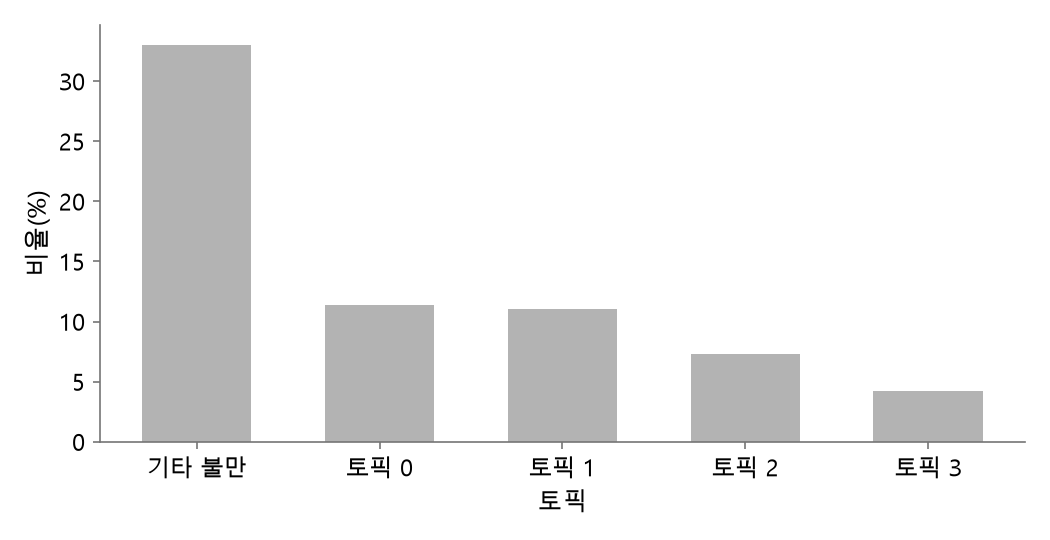

In [7]:
# 미션 2 — 프롬프트 (함정)   # ai: prompt
# 이 미션은 함정입니다. 아래는 전임 담당자가 남긴 코드라 오류 없이 실행되지만 틀린 표를 만듭니다.
# 어디를 어떻게 고칠지 PROMPT 에 쓰면 튜터가 AI 코드 표시선 아래를 다시 씁니다.
# 고칠 지시는 AI 튜터 대화창이 아니라 아래 PROMPT 따옴표 안에 적습니다. 대화창에만 쓰면 진단은 나오지만 완성본 풀이가 열리지 않습니다
PROMPT = """

"""
# --- 여기부터 AI 코드 ---
# ↓ 전임 담당자의 코드 — 「가장 큰 불만은 기타 불만」이라는 결론을 낸 토픽 표. 그대로 실행하면 채점이 ❌ 를 냅니다
vc = T20K["topic"].value_counts()                                  # 토픽 번호마다 건수(−1 포함)
n_class = N_ALL - vc[-1]                                           # 분류가 된 민원 수
table = pd.DataFrame({"토픽": vc.index, "건수": vc.values})
table["비율"] = (table["건수"] / n_class * 100).round(2)            # 토픽 비율 = 건수 ÷ 분류가 된 민원 수
table.loc[table["토픽"] == -1, "비율"] = round(vc[-1] / N_ALL * 100, 2)   # 분류가 안 된 민원은 전체로 나눈다
table["상위 단어"] = [" · ".join(WORDS[k]) for k in table["토픽"]]
table.loc[table["토픽"] == -1, "상위 단어"] = "기타 불만"              # 어느 토픽에도 들지 않은 민원 = 기타 불만
table = table.sort_values("비율", ascending=False).reset_index(drop=True)
print(table.head(5).to_string(index=False))
print(f"분모 = {n_class:,} 건 (분류가 된 민원)")
print("판단 : 가장 큰 불만은 「기타 불만」(33.05%)이고, 휴대폰 개통·요금 불만이 11.39% 로 뒤를 잇는다")

top5 = table.head(5)
fig, ax = plt.subplots(figsize=(FIG_W * 0.7, 3.6))
ax.bar(["기타 불만" if k == -1 else f"토픽 {k}" for k in top5["토픽"]], top5["비율"],
       color=COL["연회색"], width=0.6)
ax.set_xlabel("토픽")
ax.set_ylabel("비율(%)")
plt.show()

1위 토픽 비율 = 7.62 %
토픽 비율 합 = 66.95 %
토픽 40개 + 이상치 1행 = 41항목, 분모 = 20,000 건 (전체 민원)
 토픽   건수   비율                    상위 단어
  0 1525 7.62 개통 · 요금 · 휴대폰 · 철회 · 인터넷
  1 1484 7.42  여행 · 항공 · 취소 · 예약 · 코로나
  2  983 4.92  자동차 · 차량 · 수리 · 중고 · 사고
  3  566 2.83  헬스장 · 헬스 · 중도 · 해지 · 환불
  4  478 2.39 정수기 · 렌탈 · 코웨이 · 비데 · 지연


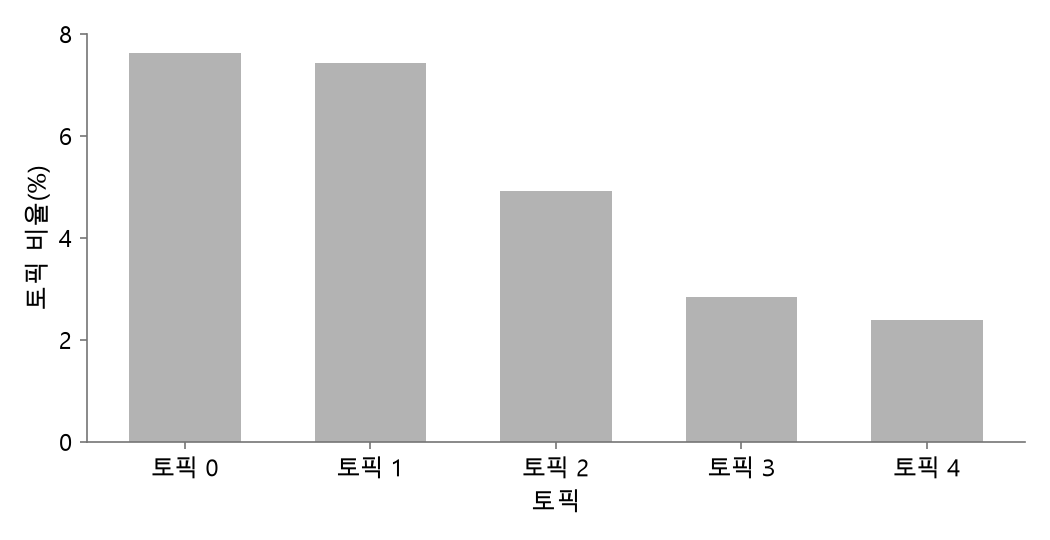

In [8]:
# 미션 2 — 프롬프트 (함정)   # ai: prompt
# 이 미션은 함정입니다. 아래는 전임 담당자가 남긴 코드라 오류 없이 실행되지만 틀린 표를 만듭니다.
# 어디를 어떻게 고칠지 PROMPT 에 쓰면 튜터가 AI 코드 표시선 아래를 다시 씁니다.
# 고칠 지시는 AI 튜터 대화창이 아니라 아래 PROMPT 따옴표 안에 적습니다. 대화창에만 쓰면 진단은 나오지만 완성본 풀이가 열리지 않습니다
PROMPT = """
전임 담당자의 코드를 수정해야해
토픽 번호에서 -1이 포함되어서 이상치의 토픽이 들어간거 같아

1. 1위 토픽 비율: %, 소수 둘째 자리, 이상치 제거 후 1위 토픽의 건수 / N_ALL * 100
2. 토픽 비율 합: %, 소수 둘째 자리, 이상치를 뺀 토픽 40개의 비율 합
3. 토픽 표: 열 '토픽', '건수', '비율', '상위 단어'인 DataFrame
4. 그래프
가로축: 토픽
세로축: 토픽 비율(%)
"""
# --- 여기부터 AI 코드 ---
vc = T20K["topic"].value_counts()                                   # 토픽 번호마다 건수(−1 포함)
table = pd.DataFrame({"토픽": vc.index, "건수": vc.values})
table["비율"] = (table["건수"] / N_ALL * 100).round(2)                # 모든 행의 분모는 전체 민원 N_ALL
table["상위 단어"] = [("" if k == -1 else " · ".join(WORDS[k])) for k in table["토픽"]]

is_out = table["토픽"] == -1
body = table[~is_out].sort_values("건수", ascending=False, kind="stable")   # 이상치를 뺀 토픽만 순위를 매긴다
table = pd.concat([body, table[is_out]]).reset_index(drop=True)             # 이상치는 이름 없이 맨 아래 한 행

top_ratio = round(body["건수"].iloc[0] / N_ALL * 100, 2)
sum_ratio = round(body["건수"].sum() / N_ALL * 100, 2)
print(f"1위 토픽 비율 = {top_ratio:.2f} %")
print(f"토픽 비율 합 = {sum_ratio:.2f} %")
print(f"토픽 {len(body)}개 + 이상치 1행 = {len(table)}항목, 분모 = {N_ALL:,} 건 (전체 민원)")
print(table.head(5).to_string(index=False))

top5 = body.head(5)
fig, ax = plt.subplots(figsize=(FIG_W * 0.7, 3.6))
ax.bar([f"토픽 {k}" for k in top5["토픽"]], top5["비율"], color=COL["연회색"], width=0.6)
ax.set_xlabel("토픽")
ax.set_ylabel("토픽 비율(%)")
plt.show()